# Analiza korelacji parametrów F1 — Austrian GP i Azerbaijan GP 2025 (wyścigi)
**Zakres:** 2 tory, **tylko wyścigi** (Race). **Źródło:** `TracingInsights-Archive/2025` (surowe JSON-y).

**Cel:** przejrzeć **wszystkie** dostępne parametry (pomiar czasu, prędkości, opony, pozycja, pogoda, telemetria) i znaleźć **najważniejsze powiązania między nimi** — bez zakładania z góry, co ma być przewidywane. Wynik ma wskazać, gdzie w danych są silne i powtarzalne zależności, które warto potem wykorzystać przy budowie modelu.

**Cache (dane pobierane tylko raz):**
1. Przy pierwszym uruchomieniu RAW jest klonowany do tymczasowego `/content` (nie na Drive), parsowany i zapisywany jako parquet w `MyDrive/F1-Research/cache/`.
2. Każde kolejne uruchomienie tylko wczytuje parquet — bez pobierania i bez parsowania.
3. Nowa runda w `EVENTS` → pobierana jest tylko ta brakująca. `FORCE_DOWNLOAD=True` wymusza pełne odświeżenie.

Wyniki (CSV + PNG) lądują w `MyDrive/F1-Research/reports/`, a na końcu notebook pakuje je do ZIP i pobiera na komputer.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Colab ma już pandas/numpy/scipy/seaborn/statsmodels/sklearn; doinstalowujemy tylko brakujące
import importlib.util, subprocess, sys
need=[p for p,m in [('pyarrow','pyarrow'),('statsmodels','statsmodels'),('scikit-learn','sklearn'),('seaborn','seaborn')] if importlib.util.find_spec(m) is None]
if need: subprocess.run([sys.executable,'-m','pip','-q','install',*need],check=True)
print('Doinstalowano:',need or 'nic')

Doinstalowano: nic


## 1. Konfiguracja i ścieżki

In [3]:
from pathlib import Path
import os, shutil, json, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)

YEAR=2025
EVENTS=['Austrian Grand Prix','Azerbaijan Grand Prix']
REPO='https://github.com/TracingInsights-Archive/2025.git'

FORCE_DOWNLOAD=False          # True = pobierz i przetwórz RAW od nowa mimo istniejącego cache
KEEP_RAW=False                # True = zachowaj też surowe JSON-y na Drive (~280 MB, kopiowanie na Drive jest wolne)
SAVE_TELEMETRY_SAMPLES=True   # pełne próbki telemetrii (wszystkie okrążenia) w parquet - pod przyszłe modele
DOWNLOAD_REPORTS_ZIP=True     # na końcu pobierz ZIP z raportami na komputer

try:
    from google.colab import drive, files as colab_files
    IN_COLAB=True
except ImportError:
    IN_COLAB=False

DRIVE_OK=False
if IN_COLAB:
    TMP=Path('/content/f1-source')          # dysk lokalny maszyny Colab - szybki, znika po sesji
    try:
        if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
        DRIVE_OK=Path('/content/drive/MyDrive').exists()
    except Exception as e:
        print('Nie udało się zamontować Google Drive:',e)
    if DRIVE_OK:
        ROOT=Path('/content/drive/MyDrive/F1-Research')
    else:
        # np. Colab uruchomiony z VS Code bez zamontowanego Drive: w VS Code użyj "Colab: Mount Google Drive to Server"
        ROOT=Path('/content/F1-Research')
        print('UWAGA: zapis na dysk maszyny Colab - cache zniknie po rozłączeniu środowiska.')
else:
    ROOT=Path(os.environ.get('F1_ROOT', Path.cwd()/'F1-Research'))   # zwykły Jupyter / VS Code lokalnie
    TMP=ROOT/'_tmp_source'
CACHE=ROOT/'cache'/str(YEAR)
RAW=ROOT/'raw'/str(YEAR)
REPORTS=ROOT/'reports'
for p in (CACHE, REPORTS): p.mkdir(parents=True, exist_ok=True)
print('Colab:',IN_COLAB,'| Drive:',DRIVE_OK,'| folder projektu:',ROOT)

# Kolory torów (zwalidowane pod daltonizm; kolor zawsze z podpisem w legendzie)
EV_PAL={'Austrian Grand Prix':'#2a78d6','Azerbaijan Grand Prix':'#eb6834'}
sns.set_theme(style='whitegrid',context='notebook',rc={'axes.edgecolor':'#bbbbbb','grid.color':'#e6e6e6'})

Colab: True | Drive: True | folder projektu: /content/drive/MyDrive/F1-Research


## 2. Pobranie RAW (tylko gdy brak cache) → parquet
Z każdej rundy powstają 4 pliki:
- `*_laps.parquet` — jedno okrążenie = jeden wiersz (czasy, opony, pit, pozycja, status toru, pogoda),
- `*_lapfeat.parquet` — cechy telemetrii policzone dla każdego okrążenia (gaz, hamulec, przeciążenia, prędkości w zakrętach, jazda za rywalem),
- `*_corners.parquet` — minimalna prędkość w każdym zakręcie na każdym okrążeniu,
- `*_samples.parquet` — pełne próbki telemetrii (opcjonalnie).

`PARSER_VERSION` zwiększamy, gdy zmieni się sposób liczenia cech — wtedy cache przebuduje się sam.

In [4]:
PARSER_VERSION=2   # v2: DRS w tych danych to 0/1 (nie kody FastF1 10/12/14)
CORNER_WINDOW_M=60    # okno ±m wokół wierzchołka zakrętu przy szukaniu prędkości minimalnej
DIRTY_AIR_S=1.0       # odstęp [s] do auta z przodu uznawany za jazdę w brudnym powietrzu

LAP_COLS={'drv':'Driver','dNum':'DriverNumber','team':'Team','lap':'LapNumber','time':'LapTime',
          's1':'Sector1Time','s2':'Sector2Time','s3':'Sector3Time','compound':'Compound','stint':'Stint',
          'life':'TyreLife','fresh':'FreshTyre','pos':'Position','status':'TrackStatus',
          'pout':'PitOutTime','pin':'PitInTime','lST':'LapStartSessionTime','sesT':'LapEndSessionTime',
          'vi1':'SpeedI1','vi2':'SpeedI2','vfl':'SpeedFL','vst':'SpeedST','del':'Deleted','iacc':'IsAccurate',
          'pb':'IsPersonalBest','wAT':'AirTemp','wTT':'TrackTemp','wH':'Humidity','wP':'Pressure',
          'wR':'Rainfall','wWS':'WindSpeed','wWD':'WindDirection'}
TEXT_COLS={'Driver','DriverNumber','Team','Compound','TrackStatus'}
BOOL_COLS={'FreshTyre','Deleted','IsAccurate','IsPersonalBest','Rainfall'}

def slug(ev): return ev.split()[0].lower()
def cache_files(ev):
    s=slug(ev)
    return {k:CACHE/f'{s}_{k}.parquet' for k in ('laps','lapfeat','corners','samples')} | {'meta':CACHE/f'{s}_meta.json'}

def is_cached(ev):
    f=cache_files(ev)
    if not f['meta'].exists(): return False
    meta=json.loads(f['meta'].read_text(encoding='utf8'))
    needed=['laps','lapfeat','corners']+(['samples'] if SAVE_TELEMETRY_SAMPLES else [])
    return meta.get('parser_version')==PARSER_VERSION and all(f[k].exists() for k in needed)

def none_to_nan(values):
    return [np.nan if v is None or v=='None' else v for v in values]

def read_json(path): return json.loads(Path(path).read_text(encoding='utf8'))

def fetch_raw(events):
    """Zwraca {event: folder Race}. Używa kopii RAW z Drive, jeśli jest; brakujące klonuje raz (sparse)."""
    out={}
    todo=[ev for ev in events if FORCE_DOWNLOAD or not (RAW/ev/'Race'/'drivers.json').exists()]
    for ev in events:
        if ev not in todo: out[ev]=RAW/ev/'Race'
    if todo:
        if TMP.exists(): shutil.rmtree(TMP)
        git=['git','-c','core.longpaths=true']
        subprocess.run([*git,'clone','-q','--depth','1','--filter=blob:none','--sparse',REPO,str(TMP)],check=True)
        subprocess.run([*git,'-C',str(TMP),'sparse-checkout','set','--',*[f'{ev}/Race' for ev in todo]],check=True)
        commit=subprocess.check_output(['git','-C',str(TMP),'rev-parse','HEAD'],text=True).strip()
        print('Pobrano RAW, commit:',commit)
        for ev in todo:
            src=TMP/ev/'Race'
            if not src.is_dir(): raise RuntimeError(f'Brak {src} - sprawdź nazwę rundy w repozytorium.')
            if KEEP_RAW:
                dst=RAW/ev/'Race'
                if dst.exists(): shutil.rmtree(dst)
                shutil.copytree(src,dst); out[ev]=dst
            else:
                out[ev]=src
        fetch_raw.commit=commit
    return out

def parse_laps(race_dir, ev):
    frames=[]
    for f in sorted(race_dir.glob('*/laptimes.json')):
        x=read_json(f)
        frames.append(pd.DataFrame({new:none_to_nan(x[old]) for old,new in LAP_COLS.items() if old in x}))
    laps=pd.concat(frames,ignore_index=True)
    for c in laps.columns:
        if c in TEXT_COLS: laps[c]=laps[c].astype('string')
        elif c in BOOL_COLS: laps[c]=laps[c].astype('boolean')
        else: laps[c]=pd.to_numeric(laps[c],errors='coerce')
    laps.insert(0,'Event',ev)
    return laps.sort_values(['Driver','LapNumber']).reset_index(drop=True)

def lap_telemetry_features(t, corner_dist):
    """Agregaty jednego okrążenia. Udziały liczone wagą czasu (próbki nie są równomierne)."""
    t=t.sort_values('time')
    tm=t['time'].to_numpy(float); dt=np.diff(tm,prepend=tm[0]); total=dt.sum()
    if total<=0 or len(t)<20: return None, None
    share=lambda mask: float(dt[mask].sum()/total)
    v=t['speed'].to_numpy(float); thr=t['throttle'].to_numpy(float); brk=t['brake'].to_numpy(float)>0
    gear=t['gear'].to_numpy(float); drs=t['drs'].to_numpy(float); rpm=t['rpm'].to_numpy(float)
    ax=t['acc_x'].to_numpy(float); ay=t['acc_y'].to_numpy(float); dist=t['distance'].to_numpy(float)
    vms=v/3.6
    f={'Tel_Duration':total,
       'Speed_mean':float(np.nansum(v*dt)/total),'Speed_max':np.nanmax(v),'Speed_p10':np.nanpercentile(v,10),
       'Throttle_mean':float(np.nansum(thr*dt)/total),'FullThrottle_share':share(thr>=98),
       'Brake_share':share(brk),'Brake_events':int(np.sum(brk[1:]&~brk[:-1])),
       'Coast_share':share((thr<5)&~brk),
       'GearShifts':int(np.sum(np.diff(gear)!=0)),'RPM_mean':float(np.nansum(rpm*dt)/total),
       'DRS_share':share((drs==1)|(drs>=10)),
       'LatAcc_absmean':float(np.nansum(np.abs(ay)*dt)/total),'LatAcc_p95':np.nanpercentile(np.abs(ay),95),
       'BrakeDecel_p05':np.nanpercentile(ax,5),'TractionAcc_p95':np.nanpercentile(ax,95),
       # "energia" przekazywana przez opony: |a| * droga (proxy obciążenia opon)
       'LatLoad':float(np.nansum(np.abs(ay)*vms*dt)/1000),'LongLoad':float(np.nansum(np.abs(ax)*vms*dt)/1000)}
    ahead=t['DriverAhead'].notna().to_numpy() & (t['DriverAhead'].astype(str)!='None').to_numpy()
    gap_s=t['DistanceToDriverAhead'].to_numpy(float)/np.maximum(vms,1)
    f['DirtyAir_share']=share(ahead&(gap_s<DIRTY_AIR_S))
    f['GapAhead_median_s']=float(np.nanmedian(np.where(ahead,gap_s,np.nan))) if ahead.any() else np.nan
    corners=[]
    for d in corner_dist:
        m=np.abs(dist-d)<=CORNER_WINDOW_M
        corners.append(np.nanmin(v[m]) if m.any() else np.nan)
    f['CornerMinSpeed_mean']=float(np.nanmean(corners)) if np.isfinite(corners).any() else np.nan
    return f, corners

def parse_telemetry(race_dir, ev):
    cr=read_json(race_dir/'corners.json')
    corner_num=cr['CornerNumber']; corner_dist=cr['Distance']
    feats=[]; crn=[]; samples=[]
    for drv_dir in sorted(p for p in race_dir.iterdir() if p.is_dir()):
        for f in drv_dir.glob('*_tel.json'):
            lap=int(f.name.split('_')[0])
            t=pd.DataFrame(read_json(f)['tel']).drop(columns=['dataKey'],errors='ignore')
            t['DriverAhead']=t['DriverAhead'].replace('None',np.nan)
            for c in t.columns:
                if c!='DriverAhead': t[c]=pd.to_numeric(t[c].replace('None',np.nan),errors='coerce')
            fe,cm=lap_telemetry_features(t,corner_dist)
            if fe is None: continue
            key={'Event':ev,'Driver':drv_dir.name,'LapNumber':lap}
            feats.append(key|fe)
            crn.append(key|{f'T{n:02d}':s for n,s in zip(corner_num,cm)})
            if SAVE_TELEMETRY_SAMPLES:
                t.insert(0,'LapNumber',lap); t.insert(0,'Driver',drv_dir.name); t.insert(0,'Event',ev)
                samples.append(t)
    smp=pd.concat(samples,ignore_index=True) if samples else None
    return pd.DataFrame(feats), pd.DataFrame(crn), smp

def build_event(ev, race_dir):
    f=cache_files(ev)
    laps=parse_laps(race_dir,ev)
    feat,crn,smp=parse_telemetry(race_dir,ev)
    laps.to_parquet(f['laps'],index=False); feat.to_parquet(f['lapfeat'],index=False); crn.to_parquet(f['corners'],index=False)
    if smp is not None:
        smp['DriverAhead']=smp['DriverAhead'].astype('string')
        smp.to_parquet(f['samples'],index=False,compression='zstd')
    meta={'event':ev,'year':YEAR,'parser_version':PARSER_VERSION,'repository':REPO,
          'commit':getattr(fetch_raw,'commit',None),'n_laps':len(laps),'n_tel_laps':len(feat)}
    f['meta'].write_text(json.dumps(meta,indent=2),encoding='utf8')
    print(f'{ev}: {len(laps)} okrążeń, telemetria dla {len(feat)} okrążeń -> zapisano cache')

missing=[ev for ev in EVENTS if FORCE_DOWNLOAD or not is_cached(ev)]
if missing:
    print('Brak cache dla:',missing,'-> pobieram RAW')
    sources=fetch_raw(missing)
    for ev in missing: build_event(ev,sources[ev])
    if TMP.exists() and not KEEP_RAW: shutil.rmtree(TMP,ignore_errors=True)
else:
    print('Cache kompletny - nic nie pobieram.')

laps=pd.concat([pd.read_parquet(cache_files(ev)['laps']) for ev in EVENTS],ignore_index=True)
lapfeat=pd.concat([pd.read_parquet(cache_files(ev)['lapfeat']) for ev in EVENTS],ignore_index=True)
corners={ev:pd.read_parquet(cache_files(ev)['corners']) for ev in EVENTS}
for ev in EVENTS: print(json.loads(cache_files(ev)['meta'].read_text(encoding='utf8')))
print({p.name:f'{p.stat().st_size/1024**2:.1f} MB' for p in sorted(CACHE.glob('*.parquet'))})

Brak cache dla: ['Austrian Grand Prix', 'Azerbaijan Grand Prix'] -> pobieram RAW
Austrian Grand Prix: 1127 okrążeń, telemetria dla 1127 okrążeń -> zapisano cache
Azerbaijan Grand Prix: 968 okrążeń, telemetria dla 968 okrążeń -> zapisano cache
{'event': 'Austrian Grand Prix', 'year': 2025, 'parser_version': 2, 'repository': 'https://github.com/TracingInsights-Archive/2025.git', 'commit': None, 'n_laps': 1127, 'n_tel_laps': 1127}
{'event': 'Azerbaijan Grand Prix', 'year': 2025, 'parser_version': 2, 'repository': 'https://github.com/TracingInsights-Archive/2025.git', 'commit': None, 'n_laps': 968, 'n_tel_laps': 968}
{'austrian_corners.parquet': '0.0 MB', 'austrian_lapfeat.parquet': '0.2 MB', 'austrian_laps.parquet': '0.1 MB', 'austrian_samples.parquet': '45.6 MB', 'azerbaijan_corners.parquet': '0.1 MB', 'azerbaijan_lapfeat.parquet': '0.2 MB', 'azerbaijan_laps.parquet': '0.1 MB', 'azerbaijan_samples.parquet': '58.8 MB'}


## 3. Zbiór danych i katalog parametrów
Jeden wiersz = jedno okrążenie jednego kierowcy (dane z pomiaru czasu + pogoda + agregaty telemetrii z tego okrążenia).

Z analizy korelacji wyłączamy tylko to, co **nie jest parametrem**, albo jest kopią innej kolumny:
- identyfikatory (`Driver`, `DriverNumber`, `Team`, `Event`) — są analizowane osobno jako kategorie (sekcja 9),
- zegary sesji (`LapStartSessionTime`, `LapEndSessionTime`) — to ta sama informacja co `LapNumber`,
- `Tel_Duration` — czas okrążenia liczony z telemetrii (= `LapTime`),
- `WindDirection` — kąt (0° = 360°), korelacja liniowa nie ma dla niego sensu.

**Dwa zbiory okrążeń:** *wszystkie* oraz *czyste* (zielona flaga, bez okrążenia 1, bez wjazdu/wyjazdu z boksu, bez usuniętych, czas < 107% mediany). Okrążenia za Safety Car są wolniejsze o kilkadziesiąt sekund i potrafią „wyprodukować” silne korelacje, których na normalnym tempie nie ma — dlatego główny ranking liczymy na czystych, a wpływ okrążeń nieczystych pokazujemy osobno (sekcja 7).

In [5]:
df=laps.merge(lapfeat,on=['Event','Driver','LapNumber'],how='left',validate='one_to_one')
df['IsPitInLap']=df['PitInTime'].notna()
df['IsPitOutLap']=df['PitOutTime'].notna()
df['UnderSC_VSC']=df['TrackStatus'].fillna('').str.contains('[4567]',regex=True)   # 4=SC, 5=czerwona, 6/7=VSC
base=df['TrackStatus'].eq('1').fillna(False)&~df['IsPitInLap']&~df['IsPitOutLap']&(df['LapNumber']>1)&~df['Deleted'].fillna(False)&df['LapTime'].notna()
med=df[base].groupby('Event')['LapTime'].median()
df['Clean']=base&(df['LapTime']<1.07*df['Event'].map(med))

GROUPS={
 'czasy':['LapTime','Sector1Time','Sector2Time','Sector3Time'],
 'pułapki prędkości':['SpeedI1','SpeedI2','SpeedFL','SpeedST'],
 'wyścig/opony':['LapNumber','Stint','TyreLife','Position'],
 'pogoda':['AirTemp','TrackTemp','Humidity','Pressure','WindSpeed','Rainfall'],
 'telemetria':[c for c in lapfeat.columns if c not in ('Event','Driver','LapNumber','Tel_Duration')]}
UNITS={'LapTime':'s','Sector1Time':'s','Sector2Time':'s','Sector3Time':'s','SpeedI1':'km/h','SpeedI2':'km/h','SpeedFL':'km/h',
       'SpeedST':'km/h','TyreLife':'okr.','AirTemp':'°C','TrackTemp':'°C','Humidity':'%','Pressure':'hPa','WindSpeed':'m/s',
       'Speed_mean':'km/h','Speed_max':'km/h','Speed_p10':'km/h','CornerMinSpeed_mean':'km/h','Throttle_mean':'%','RPM_mean':'obr./min',
       'GapAhead_median_s':'s'}
GROUP_OF={c:g for g,cs in GROUPS.items() for c in cs}
PARAMS=[c for cs in GROUPS.values() for c in cs]

catalog=pd.DataFrame([{'parametr':c,'grupa':GROUP_OF[c],'jednostka':UNITS.get(c,''),
    **{f'braki_%|{slug(ev)}':round(100*df.loc[df.Event.eq(ev),c].isna().mean(),1) for ev in EVENTS},
    **{f'unikalne|{slug(ev)}':df.loc[df.Event.eq(ev),c].nunique() for ev in EVENTS}} for c in PARAMS])
# parametr bez zmienności na danym torze (np. brak deszczu) nie może korelować
PARAMS=[c for c in PARAMS if all(df.loc[df.Event.eq(ev)&df.Clean,c].nunique()>2 for ev in EVENTS)]
catalog['w_analizie']=catalog.parametr.isin(PARAMS)
display(catalog); catalog.to_csv(REPORTS/'parameter_catalog.csv',index=False)

overview=df.groupby('Event').agg(okrazenia=('LapNumber','size'),kierowcy=('Driver','nunique'),dlugosc_wyscigu=('LapNumber','max'),
    czyste=('Clean','sum'),pit_stopy=('IsPitInLap','sum'),okr_SC_VSC=('UnderSC_VSC','sum'),telemetria=('Speed_mean',lambda s:round(s.notna().mean(),3)))
display(overview); overview.to_csv(REPORTS/'overview.csv')
print('Parametrów liczbowych w analizie:',len(PARAMS))

,parametr,grupa,jednostka,braki_%|austrian,braki_%|azerbaijan,unikalne|austrian,unikalne|azerbaijan,w_analizie
0,LapTime,czasy,s,0.3,0.1,978,888,True
1,Sector1Time,czasy,s,1.8,2.1,644,805,True
2,Sector2Time,czasy,s,0.3,0.1,852,800,True
3,Sector3Time,czasy,s,0.3,0.1,830,643,True
4,SpeedI1,pułapki prędkości,km/h,0.3,0.1,90,101,True
5,SpeedI2,pułapki prędkości,km/h,0.3,0.1,63,100,True
6,SpeedFL,pułapki prędkości,km/h,3.2,2.3,56,99,True
7,SpeedST,pułapki prędkości,km/h,0.3,0.1,78,70,True
8,LapNumber,wyścig/opony,,0.0,0.0,70,51,True
9,Stint,wyścig/opony,,0.0,0.0,4,3,True


,okrazenia,kierowcy,dlugosc_wyscigu,czyste,pit_stopy,okr_SC_VSC,telemetria
Event,,,,,,,
Austrian Grand Prix,1127,20,70,984,33,54,1.0
Azerbaijan Grand Prix,968,20,51,791,21,77,1.0


Parametrów liczbowych w analizie: 36


### Opis telemetrii (agregaty z jednego okrążenia)
| parametr | znaczenie |
|---|---|
| `Speed_mean/max/p10` | średnia (ważona czasem), maksymalna, 10. percentyl prędkości |
| `CornerMinSpeed_mean` | średnia z minimalnych prędkości w zakrętach (okno ±60 m wokół wierzchołka) |
| `Throttle_mean`, `FullThrottle_share`, `Coast_share` | średni gaz, udział czasu na pełnym gazie, udział toczenia bez gazu i hamulca |
| `Brake_share`, `Brake_events` | udział czasu na hamulcu, liczba naciśnięć |
| `GearShifts`, `RPM_mean` | liczba zmian biegów, średnie obroty |
| `DRS_share` | udział czasu z otwartym DRS |
| `LatAcc_absmean/p95`, `BrakeDecel_p05`, `TractionAcc_p95` | przyspieszenia boczne i wzdłużne |
| `LatLoad`, `LongLoad` | Σ\|a\|·v·dt — obciążenie boczne/wzdłużne przekazywane przez opony |
| `DirtyAir_share`, `GapAhead_median_s` | udział czasu < 1 s za innym autem, mediana odstępu do auta z przodu |

## 4. Rozkłady parametrów na obu torach
Szybki przegląd: skala, skośność, wartości odstające. Rozkłady bardzo skośne lub wielomodalne to sygnał, że korelacja Pearsona może mylić — dlatego obok niej liczymy Spearmana i korelację odległości.

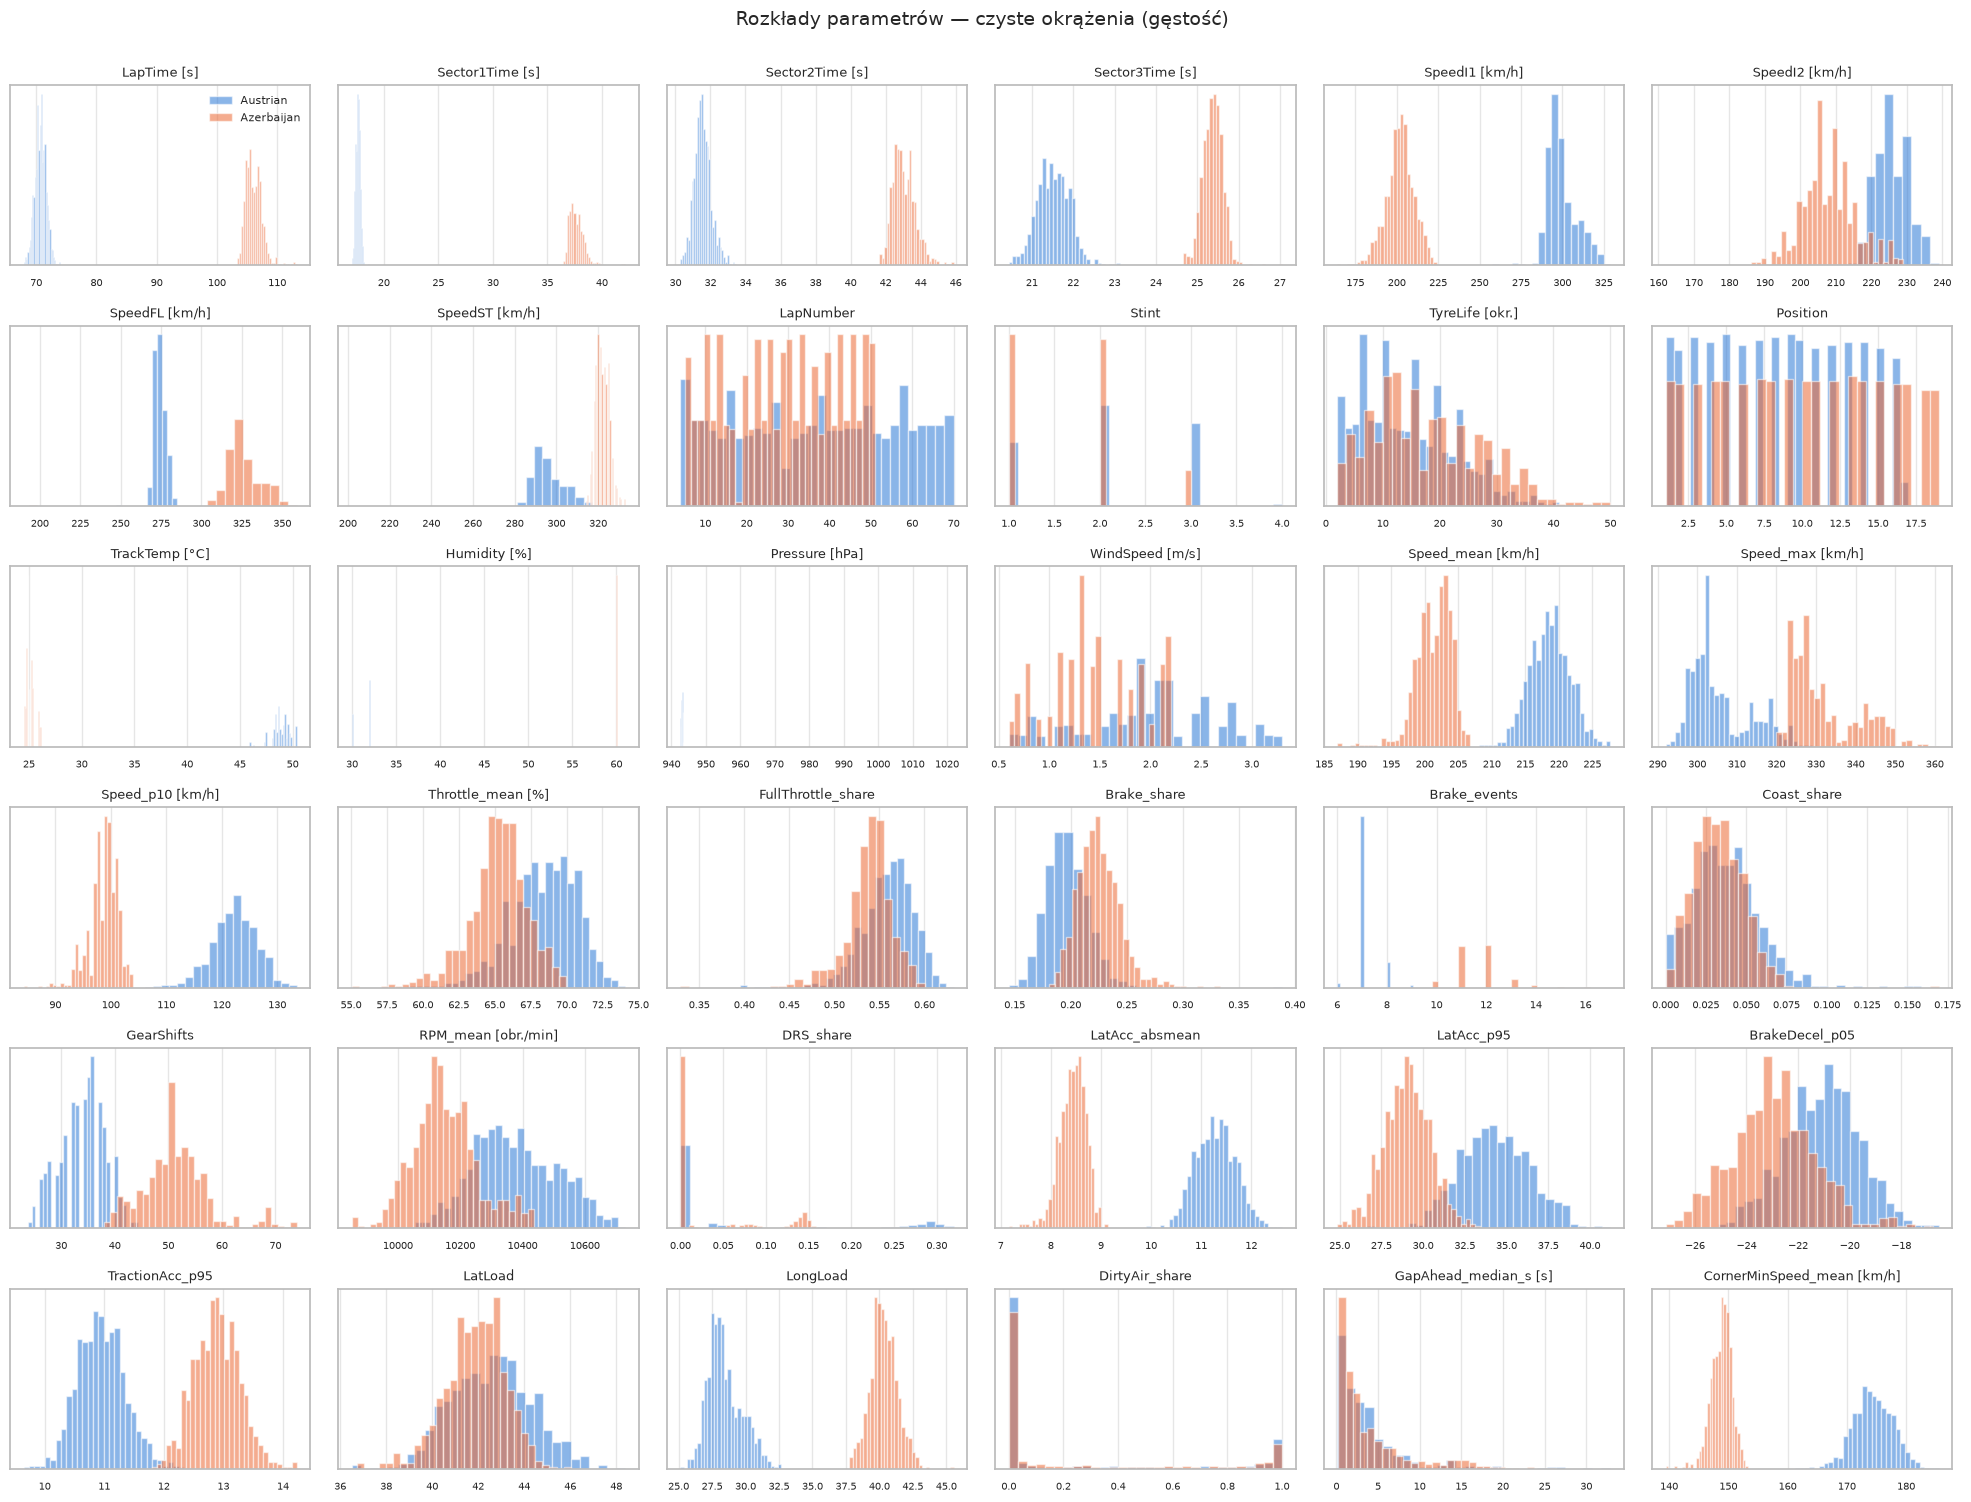

In [6]:
ncol=6; nrow=int(np.ceil(len(PARAMS)/ncol))
fig,axes=plt.subplots(nrow,ncol,figsize=(3.3*ncol,2.5*nrow))
for ax,c in zip(axes.flat,PARAMS):
    for ev in EVENTS:
        v=df.loc[df.Event.eq(ev)&df.Clean,c].dropna()
        ax.hist(v,bins=30,alpha=.55,color=EV_PAL[ev],label=ev.split()[0],density=True)
    ax.set_title(f"{c} [{UNITS[c]}]" if c in UNITS else c,fontsize=9); ax.tick_params(labelsize=7); ax.set_yticks([])
for ax in list(axes.flat)[len(PARAMS):]: ax.axis('off')
axes.flat[0].legend(fontsize=8,frameon=False)
plt.suptitle('Rozkłady parametrów — czyste okrążenia (gęstość)',y=1.0,fontsize=14)
plt.tight_layout(); plt.savefig(REPORTS/'distributions.png',dpi=130,bbox_inches='tight'); plt.show()

## 5. Macierze korelacji — wszystkie parametry
Spearman (ρ, zależność monotoniczna, odporna na wartości odstające) na czystych okrążeniach, osobno dla każdego toru. Kolejność parametrów ustala klasteryzacja — **bloki** to grupy parametrów, które niosą podobną informację. Macierze Pearsona i Spearmana dla wszystkich i czystych okrążeń są zapisywane do CSV.

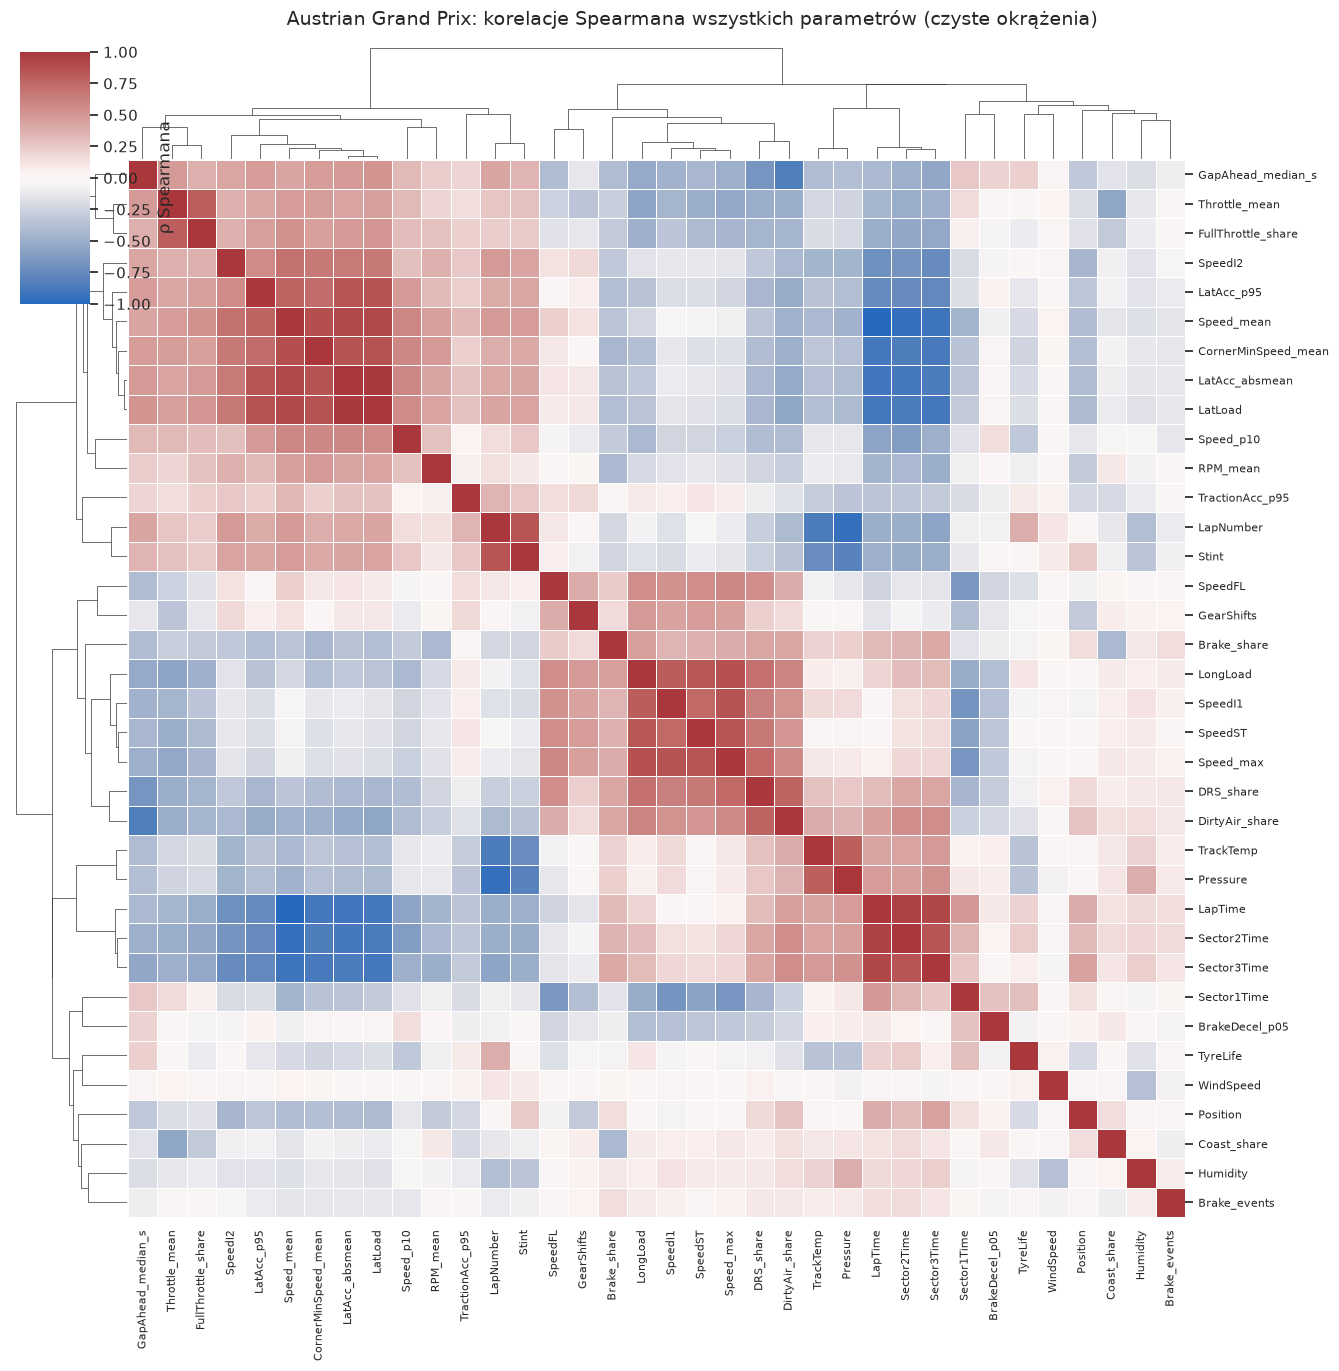

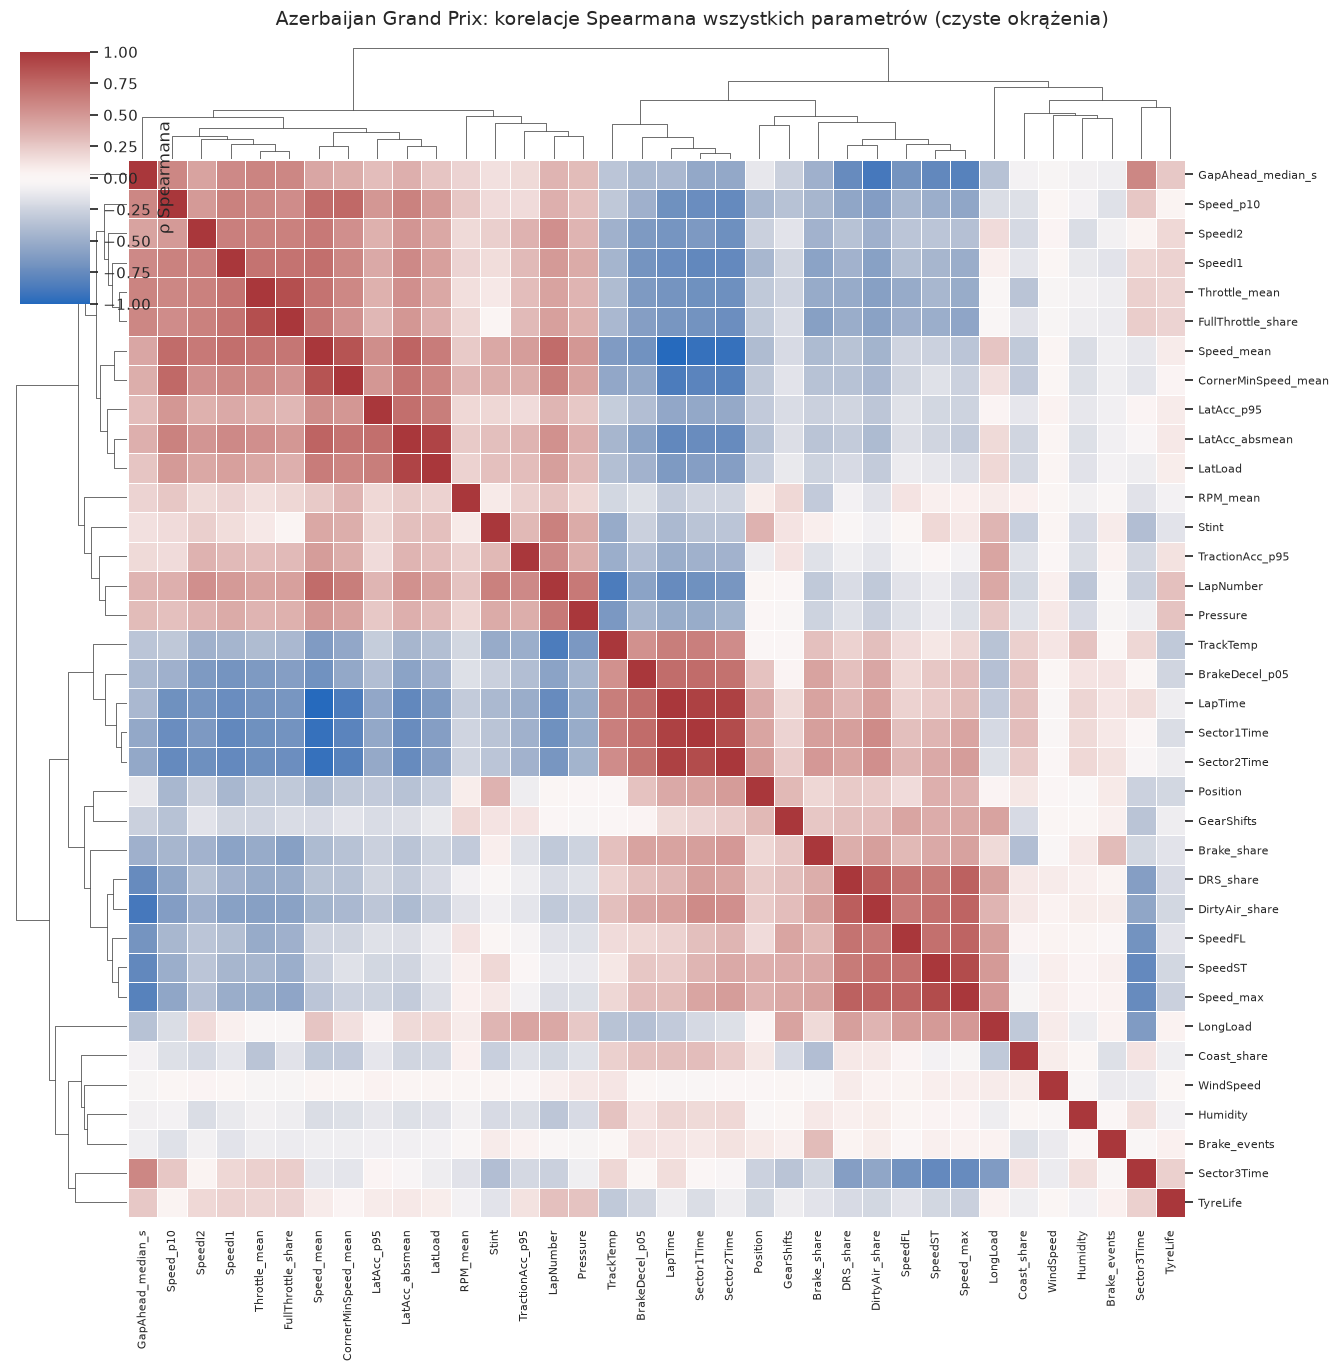

In [7]:
for ev in EVENTS:
    for subset,mask in [('clean',df.Clean),('all',pd.Series(True,index=df.index))]:
        x=df.loc[df.Event.eq(ev)&mask,PARAMS]
        for method in ('pearson','spearman'): x.corr(method=method,min_periods=30).to_csv(REPORTS/f'{slug(ev)}_{method}_{subset}.csv')
    rho=df.loc[df.Event.eq(ev)&df.Clean,PARAMS].corr(method='spearman',min_periods=30)
    cg=sns.clustermap(rho.fillna(0),cmap='vlag',vmin=-1,vmax=1,center=0,figsize=(14,14),xticklabels=True,yticklabels=True,
                      linewidths=.5,linecolor='white',cbar_kws={'label':'ρ Spearmana'},dendrogram_ratio=.1)
    cg.ax_heatmap.tick_params(labelsize=8)
    cg.fig.suptitle(f'{ev}: korelacje Spearmana wszystkich parametrów (czyste okrążenia)',y=1.01,fontsize=14)
    cg.savefig(REPORTS/f'{slug(ev)}_clustermap.png',dpi=130); plt.show()

## 6. Ranking par parametrów
Dla każdej pary i każdego toru liczymy:
| kolumna | co mierzy |
|---|---|
| `pearson`, `spearman` | korelacja liniowa / monotoniczna (czyste okrążenia) |
| `q` | p-wartość Spearmana po korekcie FDR (Benjamini–Hochberg) na wiele testów |
| `in_driver` | korelacja **wewnątrz kierowcy** (od wartości odjęta średnia kierowcy) — usuwa różnice między bolidami/kierowcami; jeśli spada do zera, ogólna korelacja wynikała tylko z tego, że szybsze auta mają „inne” wartości obu parametrów |
| `partial_lap` | korelacja cząstkowa po usunięciu `LapNumber` — usuwa wspólny trend w czasie wyścigu (np. temperatura spada i paliwo ubywa jednocześnie) |
| `dcor` | korelacja odległości (0–1) — wykrywa też zależności niemonotoniczne |
| `all_laps` | Spearman na wszystkich okrążeniach (z SC, boksami) |

**Typ pary:** `definicyjna` = jeden parametr jest liczony z drugiego lub z tego samego sygnału (np. `LapTime` = suma sektorów, `LatLoad` z `LatAcc`); te pary są oczekiwane i nie są odkryciem. `empiryczna` = wszystkie pozostałe — to one są przedmiotem analizy.

Uwaga: okrążenia jednego kierowcy nie są niezależne, więc p-wartości są optymistyczne — ważniejsza jest siła i powtarzalność (oba tory, `in_driver`).

In [8]:
from scipy import stats
DEFINITIONAL=[{'LapTime','Sector1Time','Sector2Time','Sector3Time','Speed_mean'},   # czas = suma sektorów; v_śr = dystans/czas
              {'LatAcc_absmean','LatAcc_p95','LatLoad'},{'LongLoad','BrakeDecel_p05','TractionAcc_p95'},
              {'Throttle_mean','FullThrottle_share','Coast_share'},{'Brake_share','Brake_events'},
              {'DirtyAir_share','GapAhead_median_s'},{'Speed_max','SpeedST'}]
def pair_type(a,b): return 'definicyjna' if any(a in s and b in s for s in DEFINITIONAL) else 'empiryczna'

def dcor_matrix(x, n_max=700, seed=0):
    """Korelacja odległości dla wszystkich par (na losowej próbce n_max wierszy)."""
    x=x.sample(min(n_max,len(x)),random_state=seed)
    cent={}
    for c in x:
        v=x[c].to_numpy(np.float32); ok=~np.isnan(v); v=np.where(ok,v,np.nanmean(v))
        a=np.abs(v[:,None]-v[None,:]); A=a-a.mean(0)-a.mean(1)[:,None]+a.mean(); cent[c]=A
    var={c:(A*A).mean() for c,A in cent.items()}
    out=pd.DataFrame(np.nan,index=x.columns,columns=x.columns)
    cols=list(x.columns)
    for i,a in enumerate(cols):
        for b in cols[i+1:]:
            d=(cent[a]*cent[b]).mean(); den=np.sqrt(var[a]*var[b])
            out.loc[a,b]=out.loc[b,a]=np.sqrt(max(d,0)/den) if den>0 else np.nan
    return out

def rank_resid(y,z):
    """Reszty z regresji rang y na rangach z (do korelacji cząstkowej Spearmana)."""
    ry,rz=y.rank(),z.rank(); m=ry.notna()&rz.notna()
    b=np.polyfit(rz[m],ry[m],1); return ry-(b[0]*rz+b[1])

rows=[]
for ev in EVENTS:
    d=df[df.Event.eq(ev)&df.Clean]; dall=df[df.Event.eq(ev)]
    x=d[PARAMS]; xd=x-x.groupby(d.Driver).transform('mean')
    pear=x.corr(); spear=x.corr(method='spearman'); within=xd.corr(); spear_all=dall[PARAMS].corr(method='spearman')
    resid=pd.DataFrame({c:rank_resid(x[c],d.LapNumber) for c in PARAMS if c!='LapNumber'}); partial=resid.corr()
    dc=dcor_matrix(x)
    for i,a in enumerate(PARAMS):
        for b in PARAMS[i+1:]:
            z=x[[a,b]].dropna()
            if len(z)<30: continue
            p=stats.spearmanr(z[a],z[b]).pvalue
            rows.append({'Event':ev,'param_a':a,'param_b':b,'grupa_a':GROUP_OF[a],'grupa_b':GROUP_OF[b],'typ':pair_type(a,b),'n':len(z),
                'pearson':pear.loc[a,b],'spearman':spear.loc[a,b],'p':p,'in_driver':within.loc[a,b],
                'partial_lap':partial.loc[a,b] if 'LapNumber' not in (a,b) else np.nan,'dcor':dc.loc[a,b],'all_laps':spear_all.loc[a,b]})
pairs=pd.DataFrame(rows)
pairs['q']=pairs.groupby('Event')['p'].transform(lambda p:stats.false_discovery_control(p.fillna(1)))
pairs.to_csv(REPORTS/'all_pairs_long.csv',index=False)

# tabela szeroka: oba tory obok siebie
VALS=['spearman','pearson','in_driver','partial_lap','dcor','all_laps','q']
wide=pairs.pivot_table(index=['param_a','param_b','grupa_a','grupa_b','typ'],columns='Event',values=VALS)
wide.columns=[f'{v}|{slug(e)}' for v,e in wide.columns]; wide=wide.reset_index()
sA,sB=[f'spearman|{slug(e)}' for e in EVENTS]
wide['same_sign']=np.sign(wide[sA])==np.sign(wide[sB])
wide['min_abs_rho']=wide[[sA,sB]].abs().min(axis=1)          # siła "gwarantowana" na obu torach
wide['mean_abs_rho']=wide[[sA,sB]].abs().mean(axis=1)
wide=wide.sort_values('min_abs_rho',ascending=False)
wide.to_csv(REPORTS/'pair_ranking.csv',index=False)
emp=wide[wide.typ.eq('empiryczna')]
print('Par łącznie:',len(wide),'| empirycznych:',len(emp),'| definicyjnych:',(wide.typ=='definicyjna').sum())
print('Empiryczne pary z |ρ|≥0.5 na obu torach i tym samym znakiem:',((emp.min_abs_rho>=.5)&emp.same_sign).sum())
show=['param_a','param_b',sA,sB,f'in_driver|{slug(EVENTS[0])}',f'in_driver|{slug(EVENTS[1])}',
      f'partial_lap|{slug(EVENTS[0])}',f'partial_lap|{slug(EVENTS[1])}',f'dcor|{slug(EVENTS[0])}',f'dcor|{slug(EVENTS[1])}','same_sign']
display(emp[show].head(30).round(2))

Par łącznie: 630 | empirycznych: 608 | definicyjnych: 22
Empiryczne pary z |ρ|≥0.5 na obu torach i tym samym znakiem: 47


,param_a,param_b,spearman|austrian,spearman|azerbaijan,in_driver|austrian,in_driver|azerbaijan,partial_lap|austrian,partial_lap|azerbaijan,dcor|austrian,dcor|azerbaijan,same_sign
128,LapNumber,TrackTemp,-0.87,-0.86,-0.83,-0.88,NaN,NaN,0.84,0.87,True
136,LapTime,CornerMinSpeed_mean,-0.90,-0.86,-0.89,-0.91,-0.88,-0.75,0.87,0.84,True
483,Speed_mean,CornerMinSpeed_mean,0.88,0.86,0.87,0.90,0.86,0.74,0.86,0.84,True
282,Sector2Time,CornerMinSpeed_mean,-0.85,-0.82,-0.83,-0.88,-0.83,-0.68,0.82,0.80,True
47,DRS_share,DirtyAir_share,0.78,0.80,0.84,0.85,0.75,0.80,0.86,0.88,True
489,Speed_mean,LatAcc_absmean,0.91,0.77,0.88,0.78,0.89,0.65,0.88,0.75,True
144,LapTime,LatAcc_absmean,-0.90,-0.77,-0.88,-0.77,-0.88,-0.65,0.88,0.75,True
466,Speed_max,DRS_share,0.75,0.78,0.87,0.84,0.76,0.77,0.88,0.86,True
290,Sector2Time,LatAcc_absmean,-0.89,-0.74,-0.85,-0.73,-0.86,-0.61,0.86,0.73,True
168,LatAcc_absmean,CornerMinSpeed_mean,0.85,0.69,0.83,0.72,0.83,0.53,0.82,0.68,True


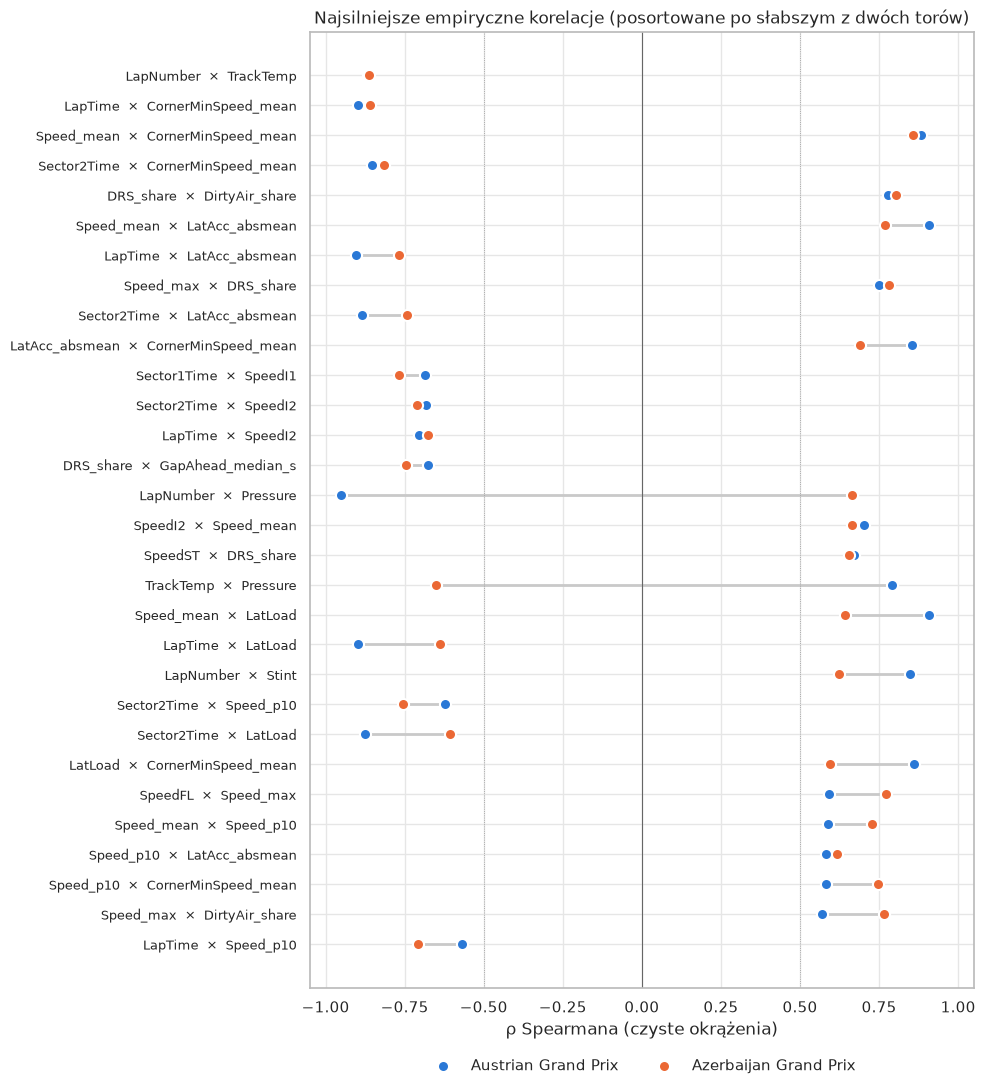

In [9]:
# Top 30 par empirycznych: ρ na każdym torze (kropki), połączone kreską
top=emp.head(30).copy(); top['para']=top.param_a+'  ×  '+top.param_b
fig,ax=plt.subplots(figsize=(10,11))
y=np.arange(len(top))[::-1]
ax.hlines(y,top[sA],top[sB],color='#c9c9c9',lw=2,zorder=1)
for col,ev in [(sA,EVENTS[0]),(sB,EVENTS[1])]:
    ax.scatter(top[col],y,s=64,color=EV_PAL[ev],edgecolor='white',linewidth=1.5,zorder=3,label=ev)
ax.set_yticks(y,top.para,fontsize=9); ax.axvline(0,color='#666',lw=.8)
for v in (-.5,.5): ax.axvline(v,color='#999',lw=.6,ls=':')
ax.set_xlim(-1.05,1.05); ax.set_xlabel('ρ Spearmana (czyste okrążenia)')
ax.set_title('Najsilniejsze empiryczne korelacje (posortowane po słabszym z dwóch torów)')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.06),ncol=2); plt.tight_layout()
plt.savefig(REPORTS/'top_pairs_dotplot.png',dpi=150); plt.show()

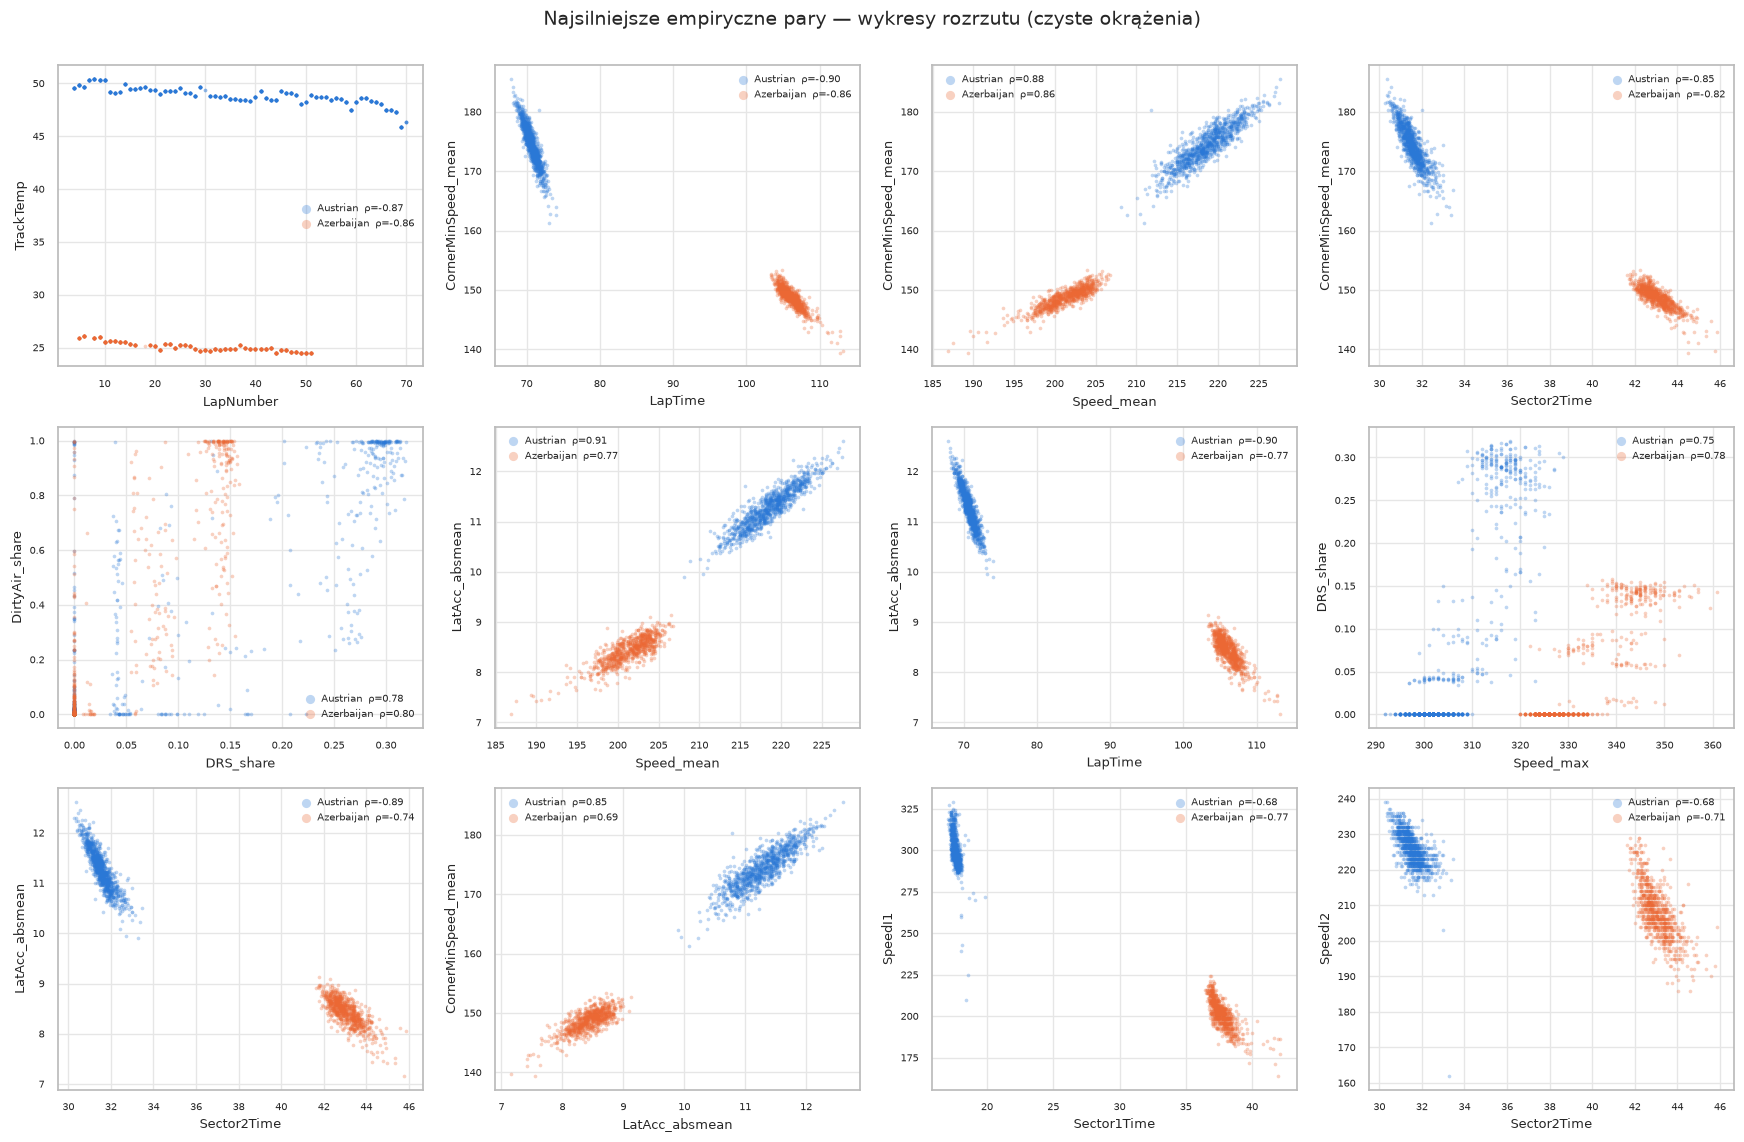

In [10]:
# Wykresy rozrzutu dla 12 najsilniejszych par empirycznych (oba tory na jednym wykresie)
TOPN=12; ncol=4; nrow=int(np.ceil(TOPN/ncol))
fig,axes=plt.subplots(nrow,ncol,figsize=(4.4*ncol,3.8*nrow))
for ax,(_,r) in zip(axes.flat,emp.head(TOPN).iterrows()):
    for ev in EVENTS:
        d=df[df.Event.eq(ev)&df.Clean]
        ax.scatter(d[r.param_a],d[r.param_b],s=7,alpha=.3,color=EV_PAL[ev],linewidths=0,
                   label=f"{ev.split()[0]}  ρ={r[f'spearman|{slug(ev)}']:.2f}")
    ax.set_xlabel(r.param_a,fontsize=9); ax.set_ylabel(r.param_b,fontsize=9); ax.tick_params(labelsize=7)
    ax.legend(fontsize=7,frameon=False,markerscale=2.5,handletextpad=.2)
for ax in list(axes.flat)[TOPN:]: ax.axis('off')
plt.suptitle('Najsilniejsze empiryczne pary — wykresy rozrzutu (czyste okrążenia)',y=1.0,fontsize=14)
plt.tight_layout(); plt.savefig(REPORTS/'top_pairs_scatter.png',dpi=140,bbox_inches='tight'); plt.show()

## 7. Co zmienia kontekst? Kierowca, czas wyścigu, okrążenia nieczyste
Każdy panel to te same pary empiryczne, oś X = zwykły ρ Spearmana (czyste okrążenia), oś Y = ρ po zmianie:
- **wewnątrz kierowcy** — punkty spadające do 0 to korelacje „między bolidami”, a nie zależność w obrębie jednego auta,
- **po usunięciu `LapNumber`** — punkty spadające do 0 to korelacje wynikające tylko ze wspólnego trendu w czasie wyścigu,
- **wszystkie okrążenia** — punkty uciekające od przekątnej to korelacje tworzone/niszczone przez okrążenia SC, pit i 1. okrążenie.

Punkty na przekątnej = korelacja odporna na dany czynnik.

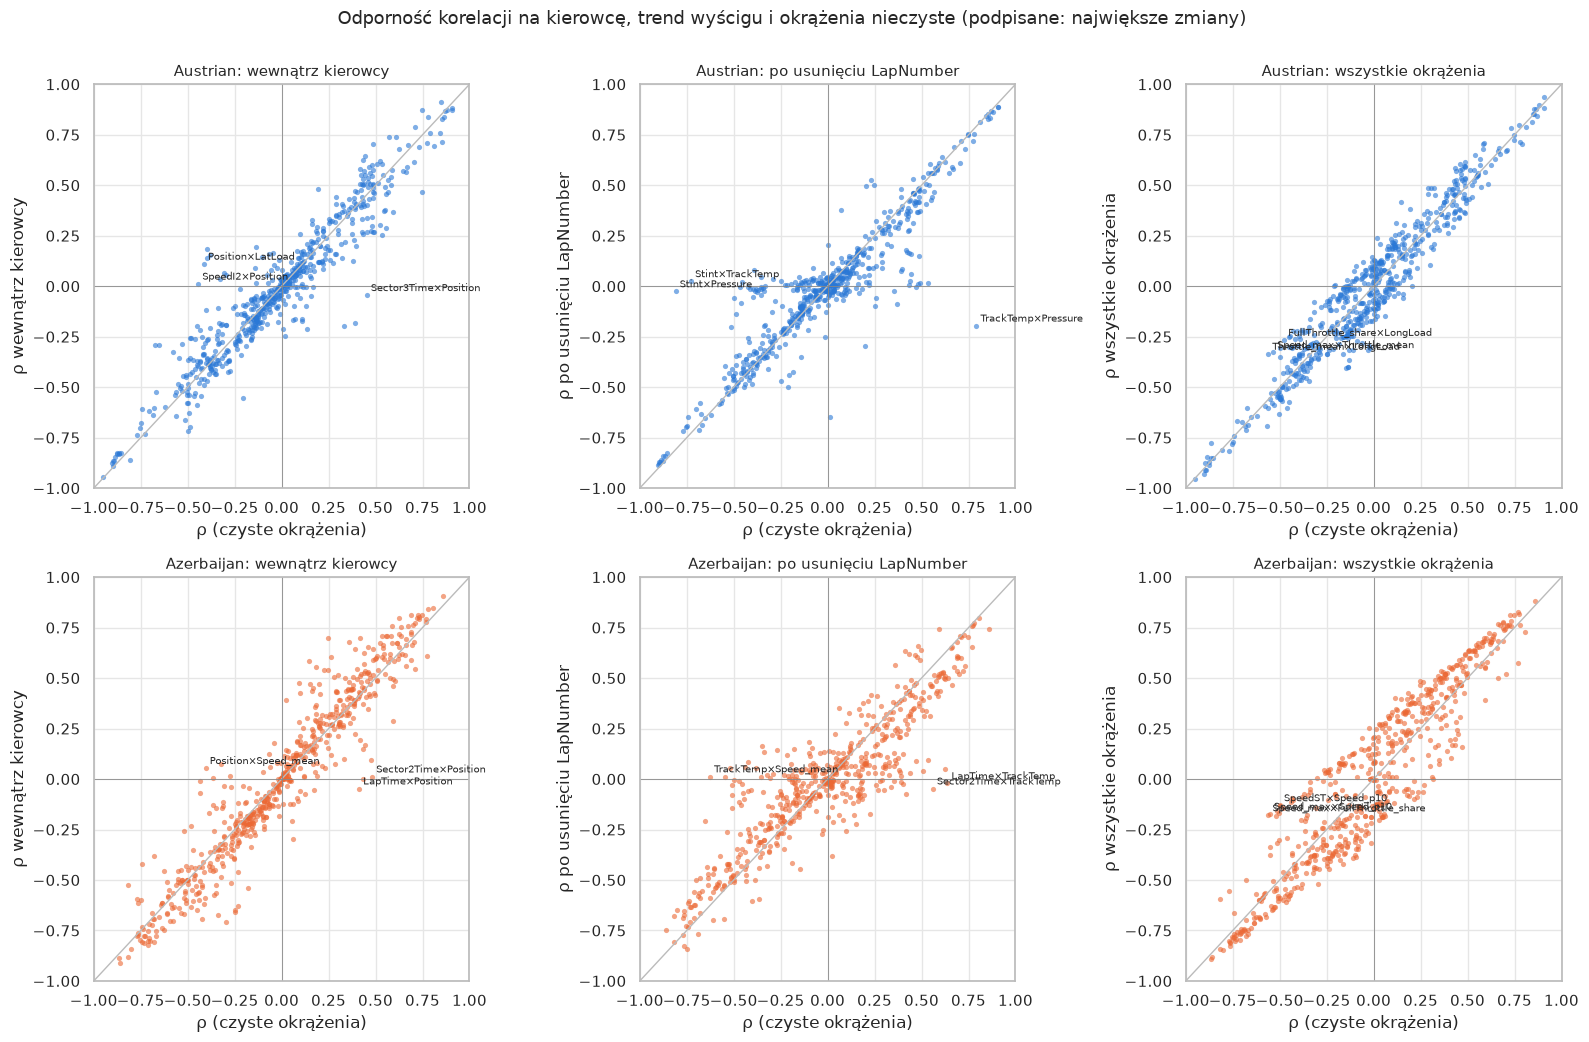

In [11]:
views=[('in_driver','wewnątrz kierowcy'),('partial_lap','po usunięciu LapNumber'),('all_laps','wszystkie okrążenia')]
fig,axes=plt.subplots(len(EVENTS),3,figsize=(16,5.2*len(EVENTS)))
for i,ev in enumerate(EVENTS):
    s=slug(ev)
    for j,(col,label) in enumerate(views):
        ax=axes[i,j]; z=emp[[f'spearman|{s}',f'{col}|{s}','param_a','param_b']].dropna()
        ax.plot([-1,1],[-1,1],color='#bbbbbb',lw=1); ax.axhline(0,color='#888',lw=.6); ax.axvline(0,color='#888',lw=.6)
        ax.scatter(z[f'spearman|{s}'],z[f'{col}|{s}'],s=14,alpha=.6,color=EV_PAL[ev],linewidths=0)
        z=z.assign(shift=(z[f'{col}|{s}']-z[f'spearman|{s}']).abs())
        for _,r in z[z[f'spearman|{s}'].abs().ge(.4)].nlargest(3,'shift').iterrows():
            ax.annotate(f'{r.param_a}×{r.param_b}',(r[f'spearman|{s}'],r[f'{col}|{s}']),fontsize=7,xytext=(3,3),textcoords='offset points')
        ax.set(xlim=(-1,1),ylim=(-1,1),xlabel='ρ (czyste okrążenia)',ylabel=f'ρ {label}')
        ax.set_title(f'{ev.split()[0]}: {label}',fontsize=11)
plt.suptitle('Odporność korelacji na kierowcę, trend wyścigu i okrążenia nieczyste (podpisane: największe zmiany)',y=1.0,fontsize=13)
plt.tight_layout(); plt.savefig(REPORTS/'correlation_robustness.png',dpi=140,bbox_inches='tight'); plt.show()

## 8. Porównanie torów i zależności nieliniowe
- Lewy wykres: ρ w Austrii vs ρ w Baku dla każdej pary. Pary blisko przekątnej są **wspólne dla obu torów**, pary w ćwiartkach o przeciwnych znakach są **specyficzne dla toru**.
- Prawy wykres: `dcor` vs |ρ|. Pary wyraźnie nad przekątną mają zależność, której Spearman nie widzi (np. kształt U, dwa skupiska).

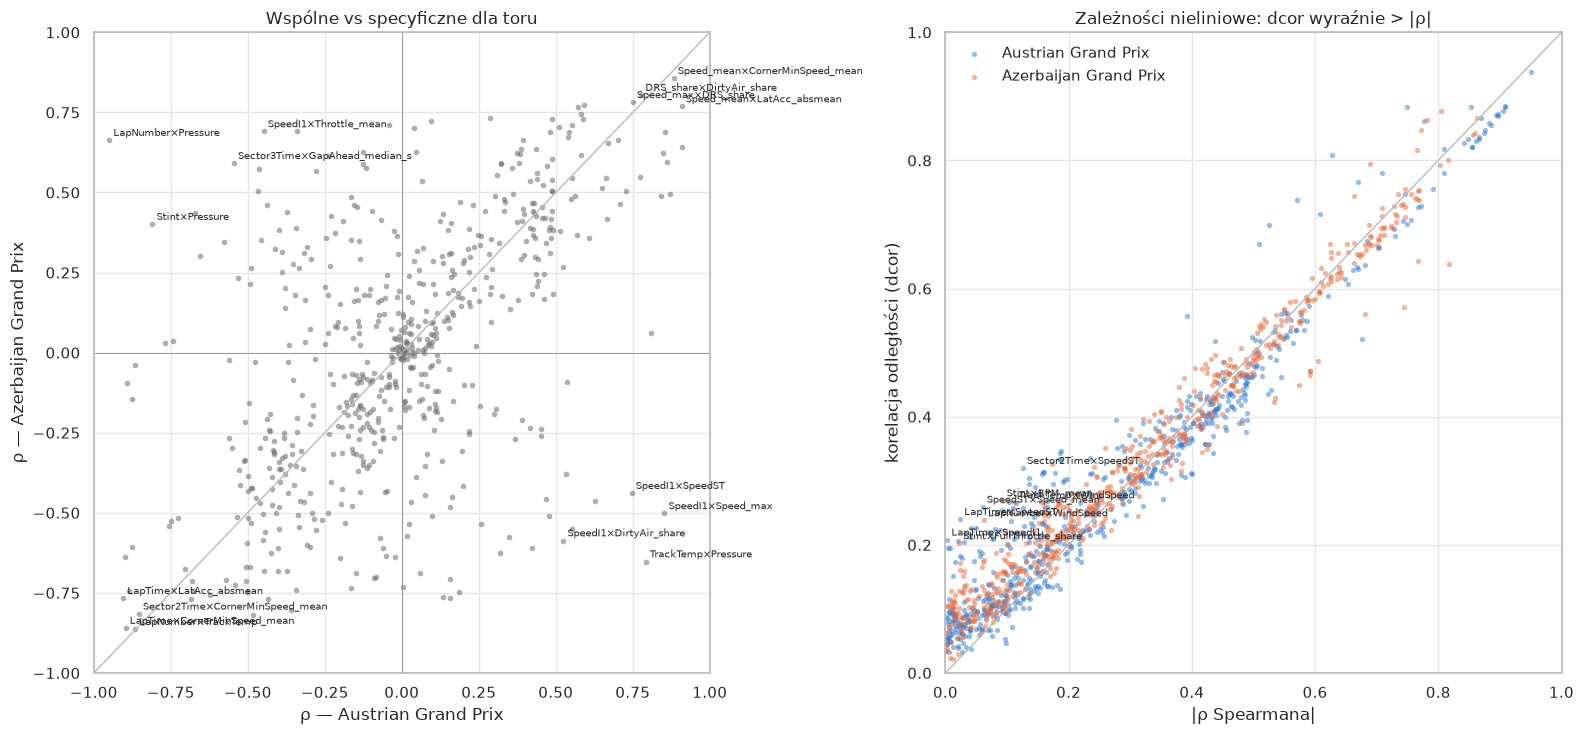

,Event,param_a,param_b,spearman,dcor,gap
6,Austrian Grand Prix,LapTime,SpeedST,0.024,0.240,0.216
3,Austrian Grand Prix,LapTime,SpeedI1,0.003,0.208,0.205
232,Austrian Grand Prix,SpeedST,Speed_mean,-0.060,0.259,0.199
73,Austrian Grand Prix,Sector2Time,SpeedST,0.126,0.320,0.194
356,Austrian Grand Prix,TrackTemp,WindSpeed,0.004,0.196,0.191
216,Austrian Grand Prix,SpeedFL,LatAcc_p95,0.007,0.195,0.188
564,Austrian Grand Prix,GearShifts,RPM_mean,0.020,0.206,0.186
145,Austrian Grand Prix,SpeedI1,Speed_mean,-0.041,0.226,0.185
155,Austrian Grand Prix,SpeedI1,DRS_share,0.627,0.809,0.182
919,Azerbaijan Grand Prix,Stint,FullThrottle_share,0.022,0.202,0.180


In [12]:
fig,axes=plt.subplots(1,2,figsize=(16,7.5))
ax=axes[0]; z=emp.dropna(subset=[sA,sB])
ax.plot([-1,1],[-1,1],color='#bbbbbb',lw=1); ax.axhline(0,color='#888',lw=.6); ax.axvline(0,color='#888',lw=.6)
ax.scatter(z[sA],z[sB],s=16,alpha=.55,color='#6b6b6b',linewidths=0)
lab=pd.concat([z.nlargest(8,'min_abs_rho'),z.assign(d=(z[sA]-z[sB]).abs()).nlargest(8,'d')]).drop_duplicates(['param_a','param_b'])
for _,r in lab.iterrows():
    ax.annotate(f'{r.param_a}×{r.param_b}',(r[sA],r[sB]),fontsize=7,xytext=(3,3),textcoords='offset points')
ax.set(xlim=(-1,1),ylim=(-1,1),xlabel=f'ρ — {EVENTS[0]}',ylabel=f'ρ — {EVENTS[1]}',title='Wspólne vs specyficzne dla toru')

ax=axes[1]
for ev in EVENTS:
    s=slug(ev); z=emp[[f'spearman|{s}',f'dcor|{s}','param_a','param_b']].dropna()
    ax.scatter(z[f'spearman|{s}'].abs(),z[f'dcor|{s}'],s=14,alpha=.5,color=EV_PAL[ev],linewidths=0,label=ev)
    z=z.assign(gap=z[f'dcor|{s}']-z[f'spearman|{s}'].abs())
    for _,r in z.nlargest(4,'gap').iterrows():
        ax.annotate(f'{r.param_a}×{r.param_b}',(abs(r[f'spearman|{s}']),r[f'dcor|{s}']),fontsize=7,xytext=(3,3),textcoords='offset points')
ax.plot([0,1],[0,1],color='#bbbbbb',lw=1); ax.set(xlim=(0,1),ylim=(0,1),xlabel='|ρ Spearmana|',ylabel='korelacja odległości (dcor)',
       title='Zależności nieliniowe: dcor wyraźnie > |ρ|'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(REPORTS/'tracks_and_nonlinear.png',dpi=140); plt.show()

nonlin=pairs[pairs.typ.eq('empiryczna')].assign(gap=lambda t:t.dcor-t.spearman.abs()).sort_values('gap',ascending=False)
nonlin.to_csv(REPORTS/'nonlinear_candidates.csv',index=False)
display(nonlin[['Event','param_a','param_b','spearman','dcor','gap']].head(10).round(3))

## 9. Parametry kategoryczne i binarne
Dla kategorii nie liczymy Pearsona na sztucznych kodach. Miarą powiązania jest **η² (współczynnik korelacji ilorazowej)** = jaka część zmienności parametru liczbowego jest wyjaśniona przez kategorię (0–1). Dla `Driver` i `Team` duże η² oznacza, że parametr zależy głównie od bolidu/kierowcy.
- `Compound`, `Team`, `Driver`, `FreshTyre` — na czystych okrążeniach,
- `TrackStatus`, `IsPitInLap`, `IsPitOutLap`, `UnderSC_VSC` — na wszystkich okrążeniach (na czystych z definicji nie występują).

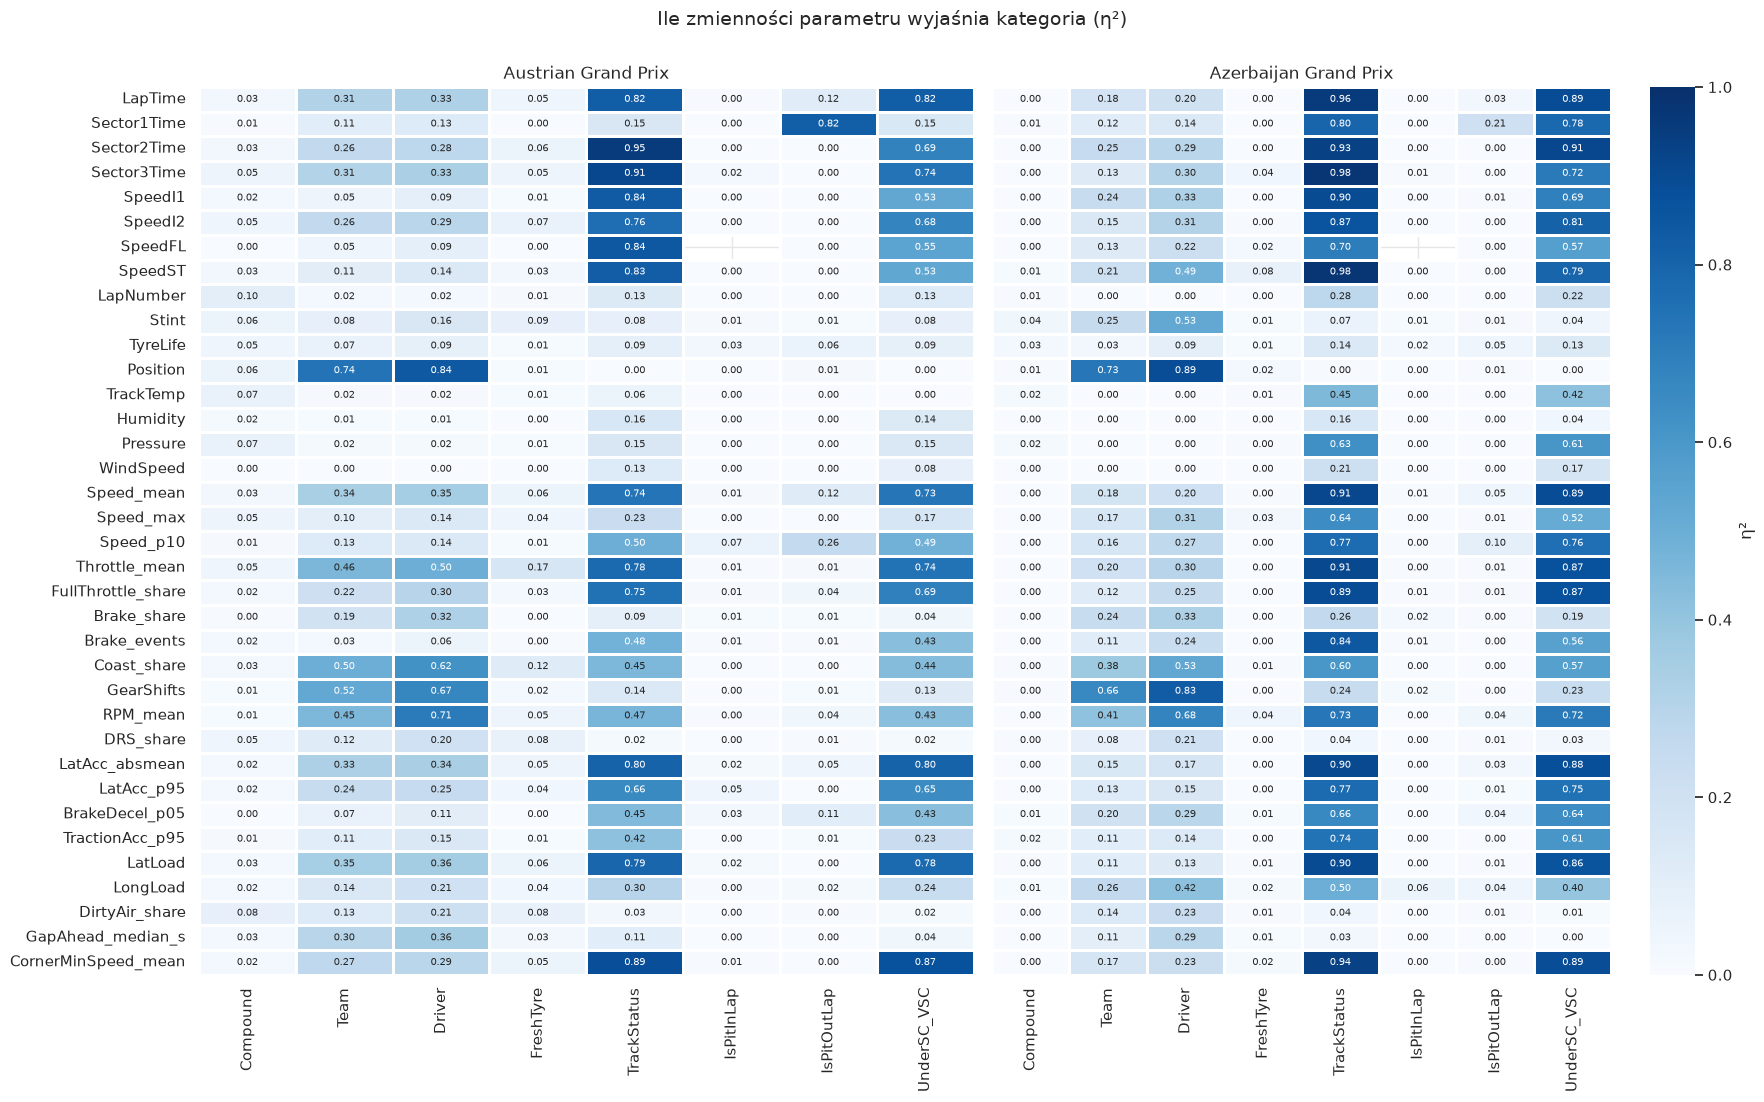

In [13]:
def eta2(y,g):
    z=pd.DataFrame({'y':y,'g':g}).dropna()
    if z.g.nunique()<2 or len(z)<30: return np.nan
    sst=((z.y-z.y.mean())**2).sum()
    ssb=z.groupby('g').y.agg(lambda s:len(s)*(s.mean()-z.y.mean())**2).sum()
    return ssb/sst if sst>0 else np.nan
CATS_CLEAN=['Compound','Team','Driver','FreshTyre']; CATS_ALL=['TrackStatus','IsPitInLap','IsPitOutLap','UnderSC_VSC']
eta_rows=[]
for ev in EVENTS:
    for cat in CATS_CLEAN+CATS_ALL:
        d=df[df.Event.eq(ev)&(df.Clean if cat in CATS_CLEAN else True)]
        for c in PARAMS: eta_rows.append({'Event':ev,'kategoria':cat,'parametr':c,'eta2':eta2(d[c],d[cat].astype(str))})
eta=pd.DataFrame(eta_rows); eta.to_csv(REPORTS/'categorical_eta2.csv',index=False)
fig,axes=plt.subplots(1,len(EVENTS),figsize=(9*len(EVENTS),11),sharey=True)
for ax,ev in zip(axes,EVENTS):
    m=eta[eta.Event.eq(ev)].pivot(index='parametr',columns='kategoria',values='eta2').loc[PARAMS,CATS_CLEAN+CATS_ALL]
    sns.heatmap(m,ax=ax,cmap='Blues',vmin=0,vmax=1,annot=True,fmt='.2f',annot_kws={'size':7},linewidths=1,linecolor='white',
                cbar=ax is axes[-1],cbar_kws={'label':'η²'})
    ax.set_title(ev); ax.set_xlabel(''); ax.set_ylabel('')
plt.suptitle('Ile zmienności parametru wyjaśnia kategoria (η²)',y=1.0,fontsize=14)
plt.tight_layout(); plt.savefig(REPORTS/'categorical_eta2.png',dpi=140,bbox_inches='tight'); plt.show()

## 10. Telemetria na poziomie próbek
Korelacje między surowymi kanałami telemetrii (prędkość, obroty, bieg, gaz, hamulec, DRS, przyspieszenia, odległość do auta z przodu) liczone na próbkach (losowe 200 tys. na tor, tylko czyste okrążenia). To pokazuje fizyczne powiązania wewnątrz okrążenia, a nie między okrążeniami.

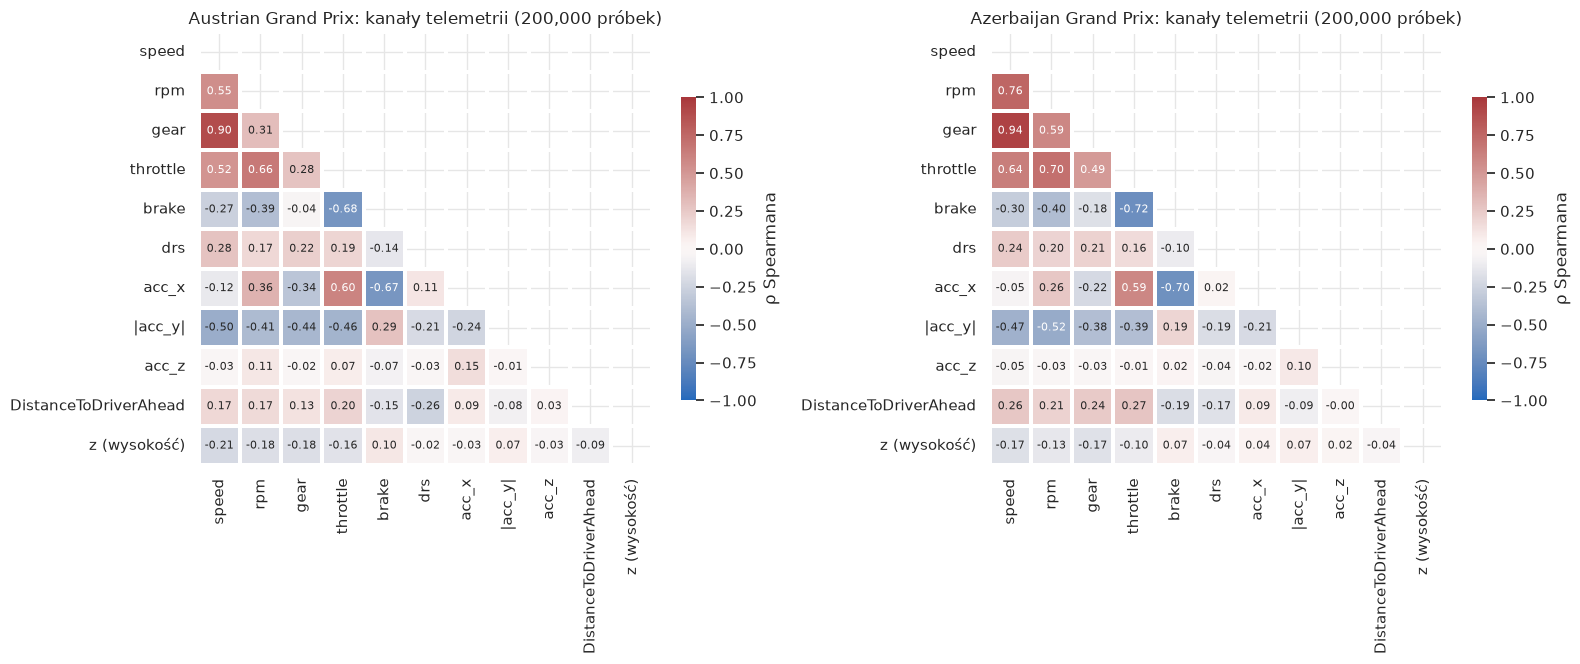

In [14]:
CH=['speed','rpm','gear','throttle','brake','drs','acc_x','acc_y','acc_z','DistanceToDriverAhead','z']
f=cache_files(EVENTS[0])['samples']
if f.exists():
    clean_keys=df.loc[df.Clean,['Event','Driver','LapNumber']]
    fig,axes=plt.subplots(1,len(EVENTS),figsize=(8*len(EVENTS),6.8))
    for ax,ev in zip(np.atleast_1d(axes),EVENTS):
        s=pd.read_parquet(cache_files(ev)['samples'],columns=['Event','Driver','LapNumber']+CH)
        s=s.merge(clean_keys,on=['Event','Driver','LapNumber'])
        s=s.sample(min(200_000,len(s)),random_state=0)
        s['acc_y']=s['acc_y'].abs()     # zakręt w lewo i w prawo = to samo obciążenie
        s=s.rename(columns={'acc_y':'|acc_y|','z':'z (wysokość)'})
        m=s.drop(columns=['Event','Driver','LapNumber']).corr(method='spearman')
        mask=np.triu(np.ones_like(m,dtype=bool))
        sns.heatmap(m,mask=mask,ax=ax,cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',annot_kws={'size':8},
                    linewidths=1.5,linecolor='white',cbar_kws={'shrink':.7,'label':'ρ Spearmana'})
        ax.set_title(f'{ev}: kanały telemetrii ({len(s):,} próbek)')
        m.to_csv(REPORTS/f'{slug(ev)}_telemetry_channels_spearman.csv')
    plt.tight_layout(); plt.savefig(REPORTS/'telemetry_channels.png',dpi=140); plt.show()
else:
    print('Brak próbek telemetrii w cache (SAVE_TELEMETRY_SAMPLES=False).')

## 11. Najważniejsze wnioski (pierwsze uruchomienie: Austria + Baku 2025, wyścigi)
Liczby: ρ Spearmana na czystych okrążeniach, Austria / Baku. Pełne tabele w `pair_ranking.csv`.

**1. Blok „tempo w zakrętach” — najsilniejsze i najbardziej powtarzalne powiązania.**
`LapTime` × `CornerMinSpeed_mean` (−0.90 / −0.86), × `LatAcc_absmean` (−0.90 / −0.77); `Sector2Time` × `CornerMinSpeed_mean` (−0.85 / −0.82). Utrzymują się wewnątrz kierowcy i po usunięciu `LapNumber` → to rzeczywista zależność okrążenie-do-okrążenia, nie efekt różnic między bolidami. Parametry `CornerMinSpeed_mean`, `LatAcc_absmean`, `LatLoad`, `Speed_p10` niosą w dużej mierze tę samą informację.

**2. Pułapki prędkości ↔ sektory.** `SpeedI1` × `Sector1Time` (−0.68 / −0.77), `SpeedI2` × `Sector2Time` (−0.68 / −0.71) — spójne na obu torach.

**3. Jazda za rywalem.** `DRS_share` × `DirtyAir_share` (0.78 / 0.80), `DRS_share` × `Speed_max` (0.75 / 0.78), `DRS_share` × `SpeedST` (0.67 / 0.65). Część tego wynika z regulaminu (DRS wolno otworzyć tylko < 1 s za rywalem), ale wpływ na prędkość maksymalną jest mierzalny. Zależność `DirtyAir_share` z `Sector3Time` i `SpeedI1` ma **przeciwny znak** na obu torach — jest specyficzna dla toru.

**4. Pogoda = głównie upływ czasu.** `TrackTemp` × `LapNumber` (−0.87 / −0.86): tor stygnie w trakcie wyścigu. `Pressure` ma trend o przeciwnym znaku na obu torach, a `TrackTemp` × `Pressure` po usunięciu `LapNumber` spada do ok. −0.2. Korelacje pogody z innymi parametrami trzeba czytać z tym zastrzeżeniem.

**5. Zależności „między bolidami”.** `Position` × `LapTime` (0.39 / 0.41) znika wewnątrz kierowcy (−0.18 / −0.05): auta z przodu są szybsze, ale u danego kierowcy pozycja nie zmienia tempa. `Position`, `GearShifts`, `RPM_mean`, `Coast_share` są w dużej mierze wyjaśniane przez `Driver`/`Team` (η² 0.5–0.9) — to cechy auta/ustawień/stylu.

**6. Opony w tych danych słabo korelują z innymi parametrami.** `Compound` wyjaśnia ≤ 10% zmienności dowolnego parametru na czystych okrążeniach; najsilniejsze powiązania `TyreLife` to `LapNumber`/`TrackTemp`/`Position` (|ρ| 0.2–0.4), czyli głównie przebieg wyścigu. Hipoteza o modelu zmiany opon **nie ma na razie mocnego oparcia w korelacjach** — wymagałaby analizy w obrębie stintów i większej liczby wyścigów.

**7. Okrążenia nieczyste (SC/VSC, pit) dominują wariancję.** `TrackStatus` wyjaśnia 82% / 96% zmienności `LapTime` na wszystkich okrążeniach. Bez ich odfiltrowania ranking korelacji pokazuje głównie różnicę „SC vs normalna jazda”.

**Ograniczenia:** tylko 2 wyścigi; okrążenia jednego kierowcy nie są niezależne (p-wartości zaniżone); korelacja ≠ przyczynowość. Kolejne rundy wystarczy dopisać do `EVENTS` — pobiorą się tylko nowe.

## 12. Zapis wyników

In [15]:
df.to_parquet(CACHE/'analysis_dataset.parquet',index=False)
print('Zbiór okrążeń z cechami:',CACHE/'analysis_dataset.parquet',df.shape)
zip_path=ROOT/'reports.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in REPORTS.glob('*'): z.write(p,p.name)
print('ZIP:',zip_path,f'{zip_path.stat().st_size/1024**2:.1f} MB')
if IN_COLAB and DOWNLOAD_REPORTS_ZIP:
    try: colab_files.download(str(zip_path))
    except Exception as e: print('Automatyczne pobieranie niedostępne (np. Colab w VS Code) - pobierz ZIP ręcznie:',zip_path,'|',e)

Zbiór okrążeń z cechami: /content/drive/MyDrive/F1-Research/cache/2025/analysis_dataset.parquet (2095, 58)
ZIP: /content/drive/MyDrive/F1-Research/reports.zip 4.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>